# Proximal Policy Optimization, from the inside

**Two examples, one algorithm:** a torque-limited **pendulum swing-up** (small, fast, used to take PPO apart
piece by piece) and the **planar quadrotor** from the RL-for-robotics lecture (used to watch a full PPO run
through its diagnostics).

In the earlier RL lecture PPO was one row in a comparison table, and in the PID-tuning lecture it was the
engine of the iterative tuner. This notebook opens it up. Everything is written from scratch in PyTorch and
NumPy - no RL library - so that every line of the algorithm is visible and can be changed.

### Learning objectives
After working through this notebook you should be able to

1. derive the policy-gradient estimator and explain why a **baseline / advantage** is subtracted;
2. compute **GAE(λ)** advantages and explain the bias-variance role of λ, *measured*, not just stated;
3. explain why plain policy gradient cannot **reuse** a batch, and how the **importance ratio** and the
   **clipped surrogate** make reuse safe;
4. relate PPO-clip to **TRPO** and to the **adaptive-KL-penalty** variant;
5. write the complete PPO loop - rollout, GAE, minibatch epochs - in ~150 lines;
6. judge which **implementation details** matter, using ablations over several seeds;
7. read the four **diagnostics** (approx. KL, clip fraction, policy std, explained variance) and say what is
   going wrong before the return curve does.

### Prerequisites
MDPs, returns, value functions and discounting (RL lecture §1-2); PyTorch autograd and `nn.Module`; the
idea of a Gaussian policy for continuous actions.

### Runtime
About **13 minutes on 2 CPU cores** (the ablation section trains 60 short PPO runs). On Linux the runs are
spread over worker processes; elsewhere they run one after another (~25 min). Set `N_SEEDS = 1` in §9 for a
quick pass - the numbers will then differ from the lecture slides, which use 3 seeds.

In [1]:
import sys, math, time, platform
import numpy as np
import torch
import torch.nn as nn
import matplotlib
import matplotlib.pyplot as plt

torch.set_num_threads(1)   # small networks: one thread is fastest and reproducible
print("python", platform.python_version(), "| numpy", np.__version__, "| torch", torch.__version__,
      "| matplotlib", matplotlib.__version__)

SURF, INK, INK2, MUTED, GRID = "#fcfcfb", "#0b0b0b", "#52514e", "#898781", "#e1e0d9"
BLUE, ORANGE, AQUA, YELLOW, RED, VIOLET = "#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e34948", "#4a3aa7"
plt.rcParams.update({
    "figure.facecolor": SURF, "axes.facecolor": SURF, "savefig.facecolor": SURF, "font.size": 10.5,
    "axes.grid": True, "axes.axisbelow": True, "grid.color": GRID, "grid.linewidth": 0.8,
    "axes.edgecolor": "#c3c2b7", "axes.labelcolor": INK2, "xtick.labelcolor": INK2, "ytick.labelcolor": INK2,
    "legend.frameon": False, "lines.linewidth": 2.0, "axes.spines.top": False, "axes.spines.right": False,
})

python 3.13.18 | numpy 2.5.3 | torch 2.15.0+cu132 | matplotlib 3.11.2


## 1. The two environments

Both environments are **vectorised NumPy**: one object steps `n` independent copies at once, which is how
PPO is normally run (many parallel actors, one learner).

**Pendulum swing-up** (the classic `Pendulum-v1` dynamics). State $(\theta,\dot\theta)$ with $\theta=0$
upright; $\ddot\theta = \tfrac{3g}{2\ell}\sin\theta + \tfrac{3}{m\ell^2}u$ at 20 Hz, torque $|u|\le 2$ N·m.
The torque is too small to lift the pendulum directly, so the policy must **pump energy** by swinging -
a genuinely non-greedy problem. Cost per step $\theta^2 + 0.1\dot\theta^2 + 0.001u^2$, 200-step episodes,
random start. A random policy scores about −1200; a good one about −150 to −180 (the start angle costs
something no matter what).

**Planar quadrotor.** The same model as the RL-for-robotics lecture: 0.80 kg, arm 0.17 m, two rotors with
a 30 ms first-order lag, 50 Hz, hover target $(x,z)=(0,1)$ m, 250-step episodes, crash on ground contact,
$|x|>2.5$ m or $|\theta|>1.4$ rad. Reward per step $1-\lVert e\rVert-0.2|\theta|-0.05\lVert v\rVert-0.02|\omega|-0.05\lVert\Delta u\rVert$, so a perfect
hover earns about 250.

Both `step` functions return `(obs, reward, terminated, truncated, final_obs)`. The distinction between
**terminated** (a real end: crash) and **truncated** (the episode clock ran out) matters for the value
targets in §6 - getting it wrong is one of the most common PPO bugs.

In [2]:
class Pendulum:
    """Torque-limited pendulum, theta=0 is upright. obs = (cos th, sin th, thdot/8)."""
    G, M, L, DT, MAX_SPEED, MAX_TORQUE, T = 10.0, 1.0, 1.0, 0.05, 8.0, 2.0, 200
    obs_dim, act_dim = 3, 1

    def __init__(self, n, seed=0):
        self.n, self.rng = n, np.random.default_rng(seed)
        self.reset_all()

    def reset_all(self):
        self.th = self.rng.uniform(-np.pi, np.pi, self.n)
        self.thd = self.rng.uniform(-1, 1, self.n)
        self.t = np.zeros(self.n, int)
        return self.obs()

    def obs(self):
        return np.stack([np.cos(self.th), np.sin(self.th), self.thd / 8.0], 1).astype(np.float32)

    def step(self, a):
        u = np.clip(a[:, 0], -1, 1) * self.MAX_TORQUE
        thn = ((self.th + np.pi) % (2 * np.pi)) - np.pi
        cost = thn ** 2 + 0.1 * self.thd ** 2 + 0.001 * u ** 2
        self.thd = np.clip(self.thd + (3 * self.G / (2 * self.L) * np.sin(self.th)
                                       + 3.0 / (self.M * self.L ** 2) * u) * self.DT,
                           -self.MAX_SPEED, self.MAX_SPEED)
        self.th = self.th + self.thd * self.DT
        self.t += 1
        trunc = self.t >= self.T
        term = np.zeros(self.n, bool)
        final_obs = self.obs()
        if trunc.any():
            k = trunc.sum()
            self.th[trunc] = self.rng.uniform(-np.pi, np.pi, k)
            self.thd[trunc] = self.rng.uniform(-1, 1, k)
            self.t[trunc] = 0
        return self.obs(), -cost, term, trunc, final_obs


class PlanarQuad:
    """Planar quadrotor hover at (0,1). Same model as the RL quadrotor lecture."""
    M, ARM, I, DRAG, G, DT, T = 0.80, 0.17, 0.006, 0.10, 9.81, 0.02, 250
    TAU_MOTOR = 0.03
    obs_dim, act_dim = 9, 2

    def __init__(self, n, seed=0, lag=None, mass_scale=1.0):
        self.n, self.rng = n, np.random.default_rng(seed)
        self.tau = self.TAU_MOTOR if lag is None else lag
        self.m = self.M * mass_scale
        self.Ii = self.I * mass_scale
        self.Th = self.M * self.G / 2          # nominal hover thrust per rotor
        self.s = np.zeros((n, 6)); self.f = np.zeros((n, 2)); self.up = np.zeros((n, 2))
        self.t = np.zeros(n, int)
        self._reset(np.ones(n, bool))

    def _reset(self, mask):
        k = mask.sum(); r = self.rng
        self.s[mask] = np.stack([r.uniform(-1, 1, k), r.uniform(0.5, 1.5, k), r.uniform(-0.4, 0.4, k),
                                 r.uniform(-0.5, 0.5, k), r.uniform(-0.5, 0.5, k), r.uniform(-1, 1, k)], 1)
        self.f[mask] = self.Th; self.up[mask] = 0.0; self.t[mask] = 0

    def obs(self):
        x, z, th, xd, zd, w = self.s.T
        return np.stack([-x, 1 - z, np.sin(th), np.cos(th), xd, zd, w / 4,
                         self.up[:, 0], self.up[:, 1]], 1).astype(np.float32)

    def step(self, a):
        u = np.clip(a, -1, 1)
        cmd = self.Th * (1 + u)
        alpha = 1.0 if self.tau <= 0 else 1 - math.exp(-self.DT / self.tau)
        self.f += alpha * (cmd - self.f)
        x, z, th, xd, zd, w = self.s.T
        F = self.f.sum(1); Mz = (self.f[:, 1] - self.f[:, 0]) * self.ARM
        xdd = (-F * np.sin(th) - self.DRAG * xd) / self.m
        zdd = (F * np.cos(th) - self.DRAG * zd) / self.m - self.G
        wd = Mz / self.Ii
        self.s += self.DT * np.stack([xd, zd, w, xdd, zdd, wd], 1)
        x, z, th, xd, zd, w = self.s.T
        e = np.hypot(x, z - 1)
        r = (1 - e - 0.2 * np.abs(th) - 0.05 * np.hypot(xd, zd) - 0.02 * np.abs(w)
             - 0.05 * np.abs(u - self.up).sum(1))
        self.up = u
        self.t += 1
        term = (z < 0) | (np.abs(x) > 2.5) | (np.abs(th) > 1.4)
        r = np.where(term, -10.0, r)
        trunc = (self.t >= self.T) & ~term
        final_obs = self.obs()
        done = term | trunc
        if done.any():
            self._reset(done)
        return self.obs(), r, term, trunc, final_obs


ENVS = {"pendulum": Pendulum, "quad": PlanarQuad}

In [3]:
for E in (Pendulum, PlanarQuad):
    env = E(256, seed=0); ret = np.zeros(256); alive = np.ones(256, bool)
    for t in range(E.T):
        o, r, term, trunc, _ = env.step(np.random.default_rng(t).uniform(-1, 1, (256, E.act_dim)))
        ret += r * alive; alive &= ~(term | trunc)
    print(f"{E.__name__:10s} random policy: mean return {ret.mean():8.1f}")

Pendulum   random policy: mean return  -1253.3
PlanarQuad random policy: mean return     -9.0


## 2. Policy gradient, and why we subtract a baseline

A stochastic policy $\pi_\theta(a\mid s)$ - here a Gaussian whose mean is a neural network - has expected
return $J(\theta)=\mathbb E_{\tau\sim\pi_\theta}\big[\sum_t \gamma^t r_t\big]$. The **log-derivative trick**
($\nabla p = p\,\nabla\log p$) turns its gradient into an expectation we can sample:

$$\nabla_\theta J = \mathbb E\Big[\sum_t \nabla_\theta\log\pi_\theta(a_t\mid s_t)\;\Psi_t\Big]$$

where $\Psi_t$ can be the return-to-go, or the return-to-go **minus any function of the state alone**
(a *baseline* $b(s_t)$), without changing the expectation, because
$\mathbb E_{a\sim\pi}[\nabla\log\pi(a\mid s)]\,b(s) = b(s)\,\nabla\!\int\pi\,da = 0$.

Read it as a recipe: *make actions that did better than expected more likely, and the others less likely*.
With $b(s)=V(s)$, $\Psi_t$ is the **advantage** $A(s_t,a_t)=Q(s_t,a_t)-V(s_t)$: how much better this action
was than the policy's average in that state.

**Why bother with the baseline?** It changes nothing in expectation but a lot in variance. The cell below
checks this on a one-step problem where the true gradient is known: a Gaussian policy $a\sim\mathcal N(\mu,1)$
with reward $r(a)=20-(a-1)^2$, so $\partial J/\partial\mu = -2(\mu-1) = 2$ at $\mu=0$. The constant 20 is the
point: shifting every reward up by a constant should not change what is learned, but without a baseline it
inflates the noise.

In [4]:
rng = np.random.default_rng(0); mu, n, reps = 0.0, 32, 4000
g_plain, g_base = [], []
for _ in range(reps):
    a = rng.normal(mu, 1.0, n); r = 20 - (a - 1) ** 2
    score = (a - mu)                       # d/dmu log N(a; mu, 1)
    g_plain.append(np.mean(score * r))
    g_base.append(np.mean(score * (r - r.mean())))
for name, g in [("no baseline", g_plain), ("baseline = batch mean", g_base)]:
    print(f"{name:22s} mean {np.mean(g):5.2f} (true 2.00)   std {np.std(g):5.2f}")
print(f"variance reduction: {np.var(g_plain) / np.var(g_base):.1f}x for the same 32 samples")

no baseline            mean  2.00 (true 2.00)   std  2.92
baseline = batch mean  mean  1.95 (true 2.00)   std  0.74
variance reduction: 15.8x for the same 32 samples


Same mean, about a 16-fold smaller variance: the baseline removed the useless constant 20 that every
sample was being multiplied by. (The batch-mean baseline is very slightly biased because it uses
the same samples; with a learned $V(s)$ from other data it is exactly unbiased.)

### The actor-critic network
The policy outputs the mean of a diagonal Gaussian; its log-std is a free parameter (state-independent, the
standard choice for continuous control). The critic $V_\phi(s)$ is a separate network. Two
details that §9 tests: **orthogonal initialisation** with a tiny gain (0.01) on the policy's last layer, so
the initial policy is close to "zero action" with uniform exploration, and a **running observation
normaliser**.

In [5]:
class RunningNorm:
    def __init__(self, dim):
        self.mean = np.zeros(dim); self.var = np.ones(dim); self.count = 1e-4
    def update(self, x):
        bm, bv, bc = x.mean(0), x.var(0), x.shape[0]
        d = bm - self.mean; tot = self.count + bc
        self.mean = self.mean + d * bc / tot
        self.var = (self.var * self.count + bv * bc + d ** 2 * self.count * bc / tot) / tot
        self.count = tot
    def __call__(self, x):
        return np.clip((x - self.mean) / np.sqrt(self.var + 1e-8), -10, 10).astype(np.float32)


def mlp(i, o, h=64, out_gain=1.0, ortho=True):
    net = nn.Sequential(nn.Linear(i, h), nn.Tanh(), nn.Linear(h, h), nn.Tanh(), nn.Linear(h, o))
    if ortho:
        for k, m in enumerate([net[0], net[2], net[4]]):
            nn.init.orthogonal_(m.weight, math.sqrt(2) if k < 2 else out_gain)
            nn.init.zeros_(m.bias)
    return net


class ActorCritic(nn.Module):
    """Diagonal Gaussian policy (state-independent log-std) + separate value network."""
    def __init__(self, obs_dim, act_dim, ortho=True, h=64, log_std0=-0.5):
        super().__init__()
        self.pi = mlp(obs_dim, act_dim, h, 0.01, ortho)
        self.v = mlp(obs_dim, 1, h, 1.0, ortho)
        self.log_std = nn.Parameter(torch.full((act_dim,), float(log_std0)))
    def dist(self, o):
        return torch.distributions.Normal(self.pi(o), self.log_std.exp())
    def value(self, o):
        return self.v(o).squeeze(-1)

## 3. Generalised advantage estimation (GAE)

We never know $A(s,a)$; we estimate it from one sampled trajectory and the critic. Define the **TD error**

$$\delta_t = r_t + \gamma V(s_{t+1}) - V(s_t).$$

Two extreme estimators:

| estimator | formula | bias | variance |
|---|---|---|---|
| one-step TD | $\hat A_t=\delta_t$ | high - inherits every error in $V$ | low - one random reward |
| Monte Carlo | $\hat A_t=\sum_l\gamma^l r_{t+l}-V(s_t)$ | none (for the gradient) | high - sums all future randomness |

GAE (Schulman et al., 2016) blends them with an exponential weight $\lambda\in[0,1]$:

$$\hat A_t^{\text{GAE}(\gamma,\lambda)} = \sum_{l\ge 0}(\gamma\lambda)^l\,\delta_{t+l}
\qquad\text{computed backwards as}\qquad \hat A_t = \delta_t + \gamma\lambda\,\hat A_{t+1}.$$

$\lambda=0$ is TD, $\lambda=1$ is Monte Carlo. The value-function target is the λ-return $\hat A_t + V(s_t)$.

The code below is the whole of GAE. Note the two masks: `term` stops the **bootstrap** (no value after a
crash), `done` stops the **recursion** (the next sample belongs to a new episode). A time-out is `done` but
not `term`, so its last step still bootstraps from $V$ of the true final state.

In [6]:
def gae(rew, val, next_val, term, done, gamma, lam):
    """rew,val,next_val,term,done: (T, N). next_val is V(s_{t+1}) using the TRUE next state
    (final obs before auto-reset), so time-outs bootstrap and terminations do not."""
    T = rew.shape[0]
    adv = np.zeros_like(rew); last = 0.0
    for t in reversed(range(T)):
        delta = rew[t] + gamma * next_val[t] * (1 - term[t]) - val[t]
        last = delta + gamma * lam * (1 - done[t]) * last
        adv[t] = last
    return adv, adv + val

### Measuring the bias-variance trade-off
"λ trades bias for variance" is usually stated, not shown. We can measure it. Take a policy in the middle
of learning (a pendulum PPO snapshot after 24 k steps, return about -916.0), fit a critic to
its Monte-Carlo returns, then for 32 states and one fixed action each

* compute the **true** $Q(s,a)$ by averaging 1024 rollouts, and
* compute 256 independent GAE(λ) estimates, each from a single rollout.

Bias² is measured on the λ-return $\hat A+V(s)$ against $Q(s,a)$ - the critic's error at $s$ itself acts
as a baseline and cancels in the policy gradient, so it should not count. We do this twice: with a
reasonably trained critic and with a deliberately under-trained one.

In [7]:
def pend_set(env, th, thd):
    env.th, env.thd, env.t = th.copy(), thd.copy(), np.zeros(len(th), int)


def pend_rollout(ac, onorm, th0, thd0, a0, H, gamma, rng_seed, V=None):
    """Roll the pendulum from given states; first action a0 (or sampled if None), then the policy.
    Returns rewards (H, n) and, if V given, values (H+1, n) on the visited states."""
    n = len(th0)
    env = Pendulum(n, seed=rng_seed); pend_set(env, th0, thd0)
    torch.manual_seed(rng_seed)
    R = np.zeros((H, n)); Vs = np.zeros((H + 1, n)) if V is not None else None
    o = env.obs()
    for t in range(H):
        ot = torch.as_tensor(onorm(o))
        with torch.no_grad():
            if V is not None: Vs[t] = V(torch.as_tensor(o)).squeeze(-1).numpy()
            a = ac.dist(ot).sample().numpy()
        if t == 0 and a0 is not None: a = a0
        o, r, _, _, _ = env.step(a)          # H < 200 so no auto-reset happens
        R[t] = r
    if V is not None:
        with torch.no_grad(): Vs[H] = V(torch.as_tensor(o)).squeeze(-1).numpy()
    return R, Vs


def disc_sum(R, gamma):
    w = gamma ** np.arange(R.shape[0])
    return (R * w[:, None]).sum(0)


def fit_critic(ac, onorm, gamma=0.95, H=100, n=4096, steps=300, seed=3):
    """Fit V(s) to Monte-Carlo returns of the policy on on-policy states. Deliberately modest
    training, so the critic is good but not perfect - like a critic in the middle of PPO."""
    rng = np.random.default_rng(seed)
    env = Pendulum(n, seed=seed); o = env.obs()
    burn = rng.integers(0, 60, n)
    for t in range(60):                           # spread states along on-policy trajectories
        with torch.no_grad(): a = ac.dist(torch.as_tensor(onorm(o))).sample().numpy()
        a[t >= burn] = a[t >= burn]
        keep_th, keep_thd = env.th.copy(), env.thd.copy()
        o, *_ = env.step(a)
        frozen = t >= burn
        env.th[frozen], env.thd[frozen] = keep_th[frozen], keep_thd[frozen]
        o = env.obs()
    th, thd = env.th.copy(), env.thd.copy()
    R, _ = pend_rollout(ac, onorm, th, thd, None, H, gamma, seed + 1)
    G = torch.as_tensor(disc_sum(R, gamma), dtype=torch.float32)
    X = torch.as_tensor(np.stack([np.cos(th), np.sin(th), thd / 8], 1).astype(np.float32))
    torch.manual_seed(seed)
    V = mlp(3, 1, 64, 1.0, True); opt = torch.optim.Adam(V.parameters(), lr=3e-3)
    mu, sd = G.mean(), G.std()
    for _ in range(steps):
        loss = ((V(X).squeeze(-1) - (G - mu) / sd) ** 2).mean()
        opt.zero_grad(); loss.backward(); opt.step()
    Vfn = lambda x: V(x) * sd + mu
    with torch.no_grad(): ev = 1 - ((Vfn(X).squeeze(-1) - G).var() / G.var()).item()
    return Vfn, ev, (th, thd)


def gae_bias_variance(ac, onorm, V, states, lams, gamma=0.95, H=100, K_true=1024, M=256, seed=11):
    """For each start state s and one fixed action a, compare GAE(lambda) estimates (M independent
    trajectories) with Monte-Carlo truth (K_true trajectories). Bias is measured on the lambda-return
    A_hat + V(s) against the true Q(s,a): the critic's error at s itself is a baseline and cancels in
    the policy gradient, so it is not counted as bias."""
    th, thd = states; S = len(th)
    rng = np.random.default_rng(seed)
    with torch.no_grad():
        o = np.stack([np.cos(th), np.sin(th), thd / 8], 1).astype(np.float32)
        a_fix = ac.dist(torch.as_tensor(onorm(o))).sample().numpy()
    rep = lambda x, k: np.repeat(x, k, 0)
    Rq, _ = pend_rollout(ac, onorm, rep(th, K_true), rep(thd, K_true), rep(a_fix, K_true), H, gamma, seed)
    Rv, _ = pend_rollout(ac, onorm, rep(th, K_true), rep(thd, K_true), None, H, gamma, seed + 1)
    Q_true = disc_sum(Rq, gamma).reshape(S, K_true).mean(1)
    A_true = Q_true - disc_sum(Rv, gamma).reshape(S, K_true).mean(1)
    R, Vs = pend_rollout(ac, onorm, rep(th, M), rep(thd, M), rep(a_fix, M), H, gamma, seed + 2, V=V)
    delta = R + gamma * Vs[1:] - Vs[:-1]                       # (H, S*M)
    out = {"lam": list(lams), "bias2": [], "var": [], "mse": []}
    for lam in lams:
        w = (gamma * lam) ** np.arange(H)
        A_hat = (delta * w[:, None]).sum(0).reshape(S, M)
        G_hat = A_hat + Vs[0].reshape(S, M)          # lambda-return: the part that carries the signal
        b2 = ((G_hat.mean(1) - Q_true) ** 2).mean(); var = A_hat.var(1).mean()
        out["bias2"].append(float(b2)); out["var"].append(float(var)); out["mse"].append(float(b2 + var))
    out["A_true_sd"] = float(A_true.std())
    return out

In [8]:
snap = {}
def grab(u, ac, on, h):
    if u == 11:
        snap["sd"] = {k: v.clone() for k, v in ac.state_dict().items()}
        snap["on"] = (on.mean.copy(), on.var.copy(), on.count)

The cell above defines a callback for the trainer. The trainer itself is built in §6; to keep the notebook
in teaching order we come back and run this experiment in §6.1, right after the trainer exists.

## 4. The data-reuse problem

Collecting 2 048 pendulum steps and then taking **one** gradient step is wasteful: simulation (or, on a
real robot, wall-clock time and hardware wear) is the expensive part. We would like to take many
optimiser steps on the same batch. But the policy-gradient formula is only valid for samples drawn from the
policy being differentiated. After the first step, the batch is **off-policy**.

The standard fix is **importance sampling**. Write $\pi_{\text{old}}$ for the policy that collected the data
and define the probability ratio

$$r_t(\theta) = \frac{\pi_\theta(a_t\mid s_t)}{\pi_{\text{old}}(a_t\mid s_t)}.$$

Then the **surrogate objective** $L^{\text{CPI}}(\theta)=\hat{\mathbb E}_t\big[r_t(\theta)\hat A_t\big]$ has
exactly the policy gradient at $\theta=\theta_{\text{old}}$ (where $r=1$), and can be evaluated for any
$\theta$ using old samples. Its flaw: it is only a good approximation of the true improvement while
$\pi_\theta$ stays close to $\pi_{\text{old}}$. Maximise it hard and the optimiser finds directions where
the ratio is huge on a few samples with large advantages - an exploit of the estimate, not an improvement
of the policy. The advantages themselves were computed for $\pi_{\text{old}}$ and go stale.

So reuse needs a **trust region**: some way to keep $\pi_\theta$ near $\pi_{\text{old}}$. §5 shows three.

## 5. Three ways to stay close: TRPO, KL penalty, clipping

**TRPO** (Schulman et al., 2015) makes the constraint explicit:

$$\max_\theta\ L^{\text{CPI}}(\theta)\quad\text{s.t.}\quad \bar D_{\text{KL}}(\pi_{\text{old}}\,\|\,\pi_\theta)\le\delta.$$

Linearising the objective and taking a quadratic model of the KL gives the **natural gradient** step
$\Delta\theta\propto F^{-1}g$, where $F$ is the Fisher information matrix (the Hessian of the KL). $F$ is
never formed: **conjugate gradient** solves $Fx=g$ using only Fisher-vector products, each costing one
double-backprop. The step is scaled so that the quadratic KL model equals δ, then a **backtracking line
search** checks the real KL and the real surrogate improvement. Correct and robust, but second-order
machinery, one big step per batch, and awkward with shared actor-critic networks or dropout.

**PPO with an adaptive KL penalty** (Schulman et al., 2017, §4) moves the constraint into the loss,
$L = L^{\text{CPI}} - \beta\,\bar D_{\text{KL}}$, uses ordinary SGD/Adam for several epochs, and adapts β
after each batch: double it if the measured KL exceeded 1.5× the target, halve it if it fell below
target/1.5.

**PPO-clip** (Schulman et al., 2017, §3) removes the KL from the loss altogether and changes the objective
so that it stops rewarding movement beyond $1\pm\epsilon$:

$$L^{\text{CLIP}}(\theta)=\hat{\mathbb E}_t\Big[\min\big(r_t(\theta)\hat A_t,\ \operatorname{clip}(r_t(\theta),1-\epsilon,1+\epsilon)\hat A_t\big)\Big].$$

The `min` makes it a **pessimistic bound**: the clip only ever removes improvement, never adds it.
Case by case:

| advantage | ratio | what $L^{\text{CLIP}}$ does |
|---|---|---|
| $\hat A>0$ (good action) | $r>1+\epsilon$ | flat - **zero gradient**: already made it likely enough |
| $\hat A>0$ | $r<1+\epsilon$ | $r\hat A$: keep pushing it up |
| $\hat A<0$ (bad action) | $r<1-\epsilon$ | flat - zero gradient: already made it unlikely enough |
| $\hat A<0$ | $r>1-\epsilon$ | $r\hat A$: keep pushing it down, **even if $r$ is far above 1** |

The last row is the subtle one: if an update accidentally made a bad action *more* likely, the clip does
not protect that mistake. The cell checks the table with autograd.

In [9]:
def l_clip(ratio, A, eps=0.2):
    return torch.min(ratio * A, ratio.clamp(1 - eps, 1 + eps) * A)

print(" A    ratio   dL/dratio")
for A in (+1.0, -1.0):
    for rv in (0.7, 0.9, 1.1, 1.3):
        r = torch.tensor(rv, requires_grad=True)
        l_clip(r, torch.tensor(A)).backward()
        print(f"{A:+.0f}    {rv:.1f}     {r.grad.item():+.1f}")

 A    ratio   dL/dratio
+1    0.7     +1.0
+1    0.9     +1.0
+1    1.1     +1.0
+1    1.3     +0.0
-1    0.7     +0.0
-1    0.9     -1.0
-1    1.1     -1.0
-1    1.3     -1.0


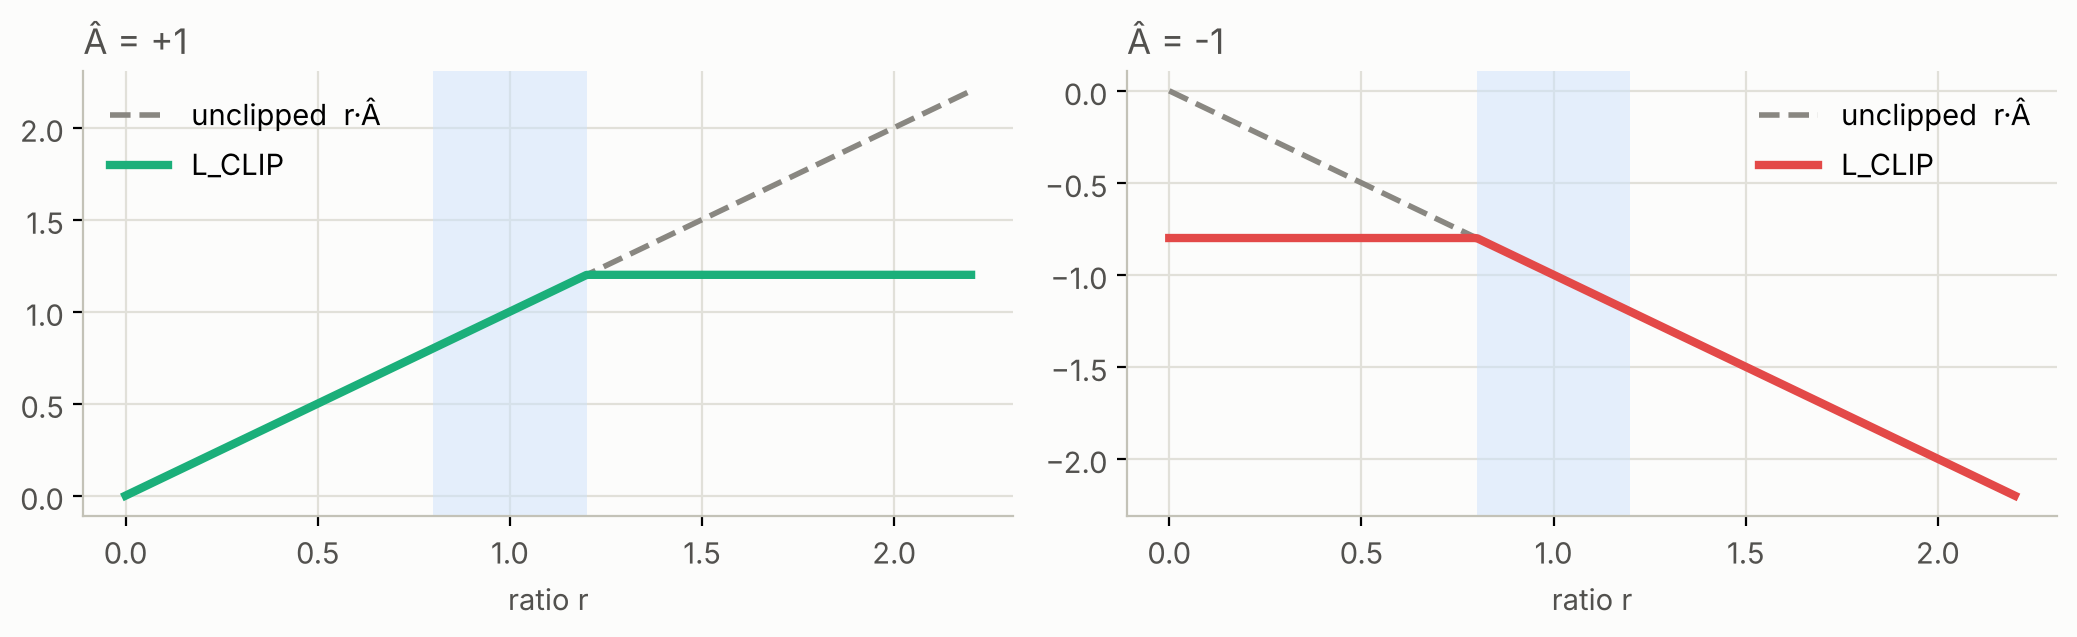

In [10]:
r = np.linspace(0, 2.2, 300); fig, ax = plt.subplots(1, 2, figsize=(10.5, 3.3))
for k, A in enumerate((1, -1)):
    ax[k].plot(r, r * A, "--", color=MUTED, label="unclipped  r·Â")
    ax[k].plot(r, np.minimum(r * A, np.clip(r, .8, 1.2) * A), color=AQUA if A > 0 else RED, lw=3, label="L_CLIP")
    ax[k].axvspan(.8, 1.2, color="#cde2fb", alpha=.5, lw=0); ax[k].set_xlabel("ratio r"); ax[k].legend()
    ax[k].set_title(f"Â = {A:+d}", loc="left", color=INK2)
plt.tight_layout(); plt.show()

## 6. PPO, complete

The algorithm (Schulman et al., 2017, Algorithm 1) is four steps repeated:

1. **Collect** $N\times T$ steps with $\pi_{\text{old}}$ ($N=8$ environments × $T=256$ steps = 2 048 samples
   for the pendulum). Store $s, a, \log\pi_{\text{old}}(a\mid s), r, V(s)$.
2. **Estimate** advantages with GAE and value targets $\hat A + V$.
3. **Optimise** $L^{\text{CLIP}} - c_v L^V$ for $K=10$ epochs over shuffled minibatches (8 per epoch → 80
   Adam steps per batch).
4. **Replace** $\pi_{\text{old}}\leftarrow\pi_\theta$ and throw the batch away (PPO is on-policy).

### 6.1 Collecting a rollout
Besides the bootstrap rule from §3, two implementation details live here: the running **observation
normaliser** is updated with every observation, and **rewards are divided by the running standard deviation
of the discounted return** (not normalised to zero mean - that would change the problem). §9 shows the
second one matters a great deal on the pendulum.

In [11]:
DEFAULTS = dict(
    env="pendulum", n_envs=8, n_steps=256, total=120_000, gamma=0.95, lam=0.95,
    epochs=10, n_mb=8, lr=1e-3, anneal=True, algo="clip", clip=0.2,
    kl_target=0.01, vclip=None, vf_coef=0.5, ent_coef=0.0, max_grad=0.5,
    adv_norm=True, obs_norm=True, rew_scale=True, ortho=True, log_std0=-0.5, h=64,
    trpo_delta=0.01, seed=0, record_update=None,
)


def evaluate(ac, env_cls, obs_norm, n=32, seed=1234, env_kwargs=None):
    """Deterministic (mean-action) return and crash rate on n fresh episodes."""
    env = env_cls(n, seed=seed, **(env_kwargs or {}))
    o = env.obs(); ret = np.zeros(n); alive = np.ones(n, bool); crashed = np.zeros(n, bool)
    for t in range(env.T):
        oo = obs_norm(o) if obs_norm is not None else o
        with torch.no_grad():
            a = ac.dist(torch.as_tensor(oo)).mean.numpy()
        o, r, term, trunc, _ = env.step(a)
        ret += r * alive; crashed |= term & alive; alive &= ~(term | trunc)
        if not alive.any():
            break
    return float(ret.mean()), float(crashed.mean())


class Rollout:
    """Runs N environments for T steps with the current policy and stores everything PPO needs."""
    def __init__(self, env, ac, c):
        self.env, self.ac, self.c = env, ac, c
        self.onorm = RunningNorm(env.obs_dim) if c["obs_norm"] else None
        self.ret_rms = RunningNorm(1); self.disc_ret = np.zeros(c["n_envs"])
        self.o = env.obs(); self.ep_ret = np.zeros(c["n_envs"]); self.finished = []

    def norm(self, o):
        return self.onorm(o) if self.onorm is not None else o

    def collect(self):
        env, ac, c = self.env, self.ac, self.c
        T, N = c["n_steps"], c["n_envs"]
        B = dict(o=np.zeros((T, N, env.obs_dim), np.float32), a=np.zeros((T, N, env.act_dim), np.float32),
                 logp=np.zeros((T, N), np.float32), r=np.zeros((T, N)), v=np.zeros((T, N)),
                 v_next=np.zeros((T, N)), term=np.zeros((T, N)), done=np.zeros((T, N)))
        for t in range(T):
            if self.onorm is not None:
                self.onorm.update(self.o)
            oo = self.norm(self.o)
            with torch.no_grad():
                ot = torch.as_tensor(oo); d = ac.dist(ot); a = d.sample()
                logp = d.log_prob(a).sum(-1); v = ac.value(ot)
            o2, r, term, trunc, final_obs = env.step(a.numpy())
            done = term | trunc
            self.ep_ret += r
            for i in np.where(done)[0]:
                self.finished.append(self.ep_ret[i]); self.ep_ret[i] = 0
            with torch.no_grad():   # V of the TRUE next state: time-outs must bootstrap
                v_next = ac.value(torch.as_tensor(self.norm(final_obs))).numpy()
            if c["rew_scale"]:      # divide by running std of the discounted return
                self.disc_ret = self.disc_ret * c["gamma"] + r
                self.ret_rms.update(self.disc_ret[:, None]); self.disc_ret[done] = 0
                r = r / math.sqrt(self.ret_rms.var[0] + 1e-8)
            B["o"][t], B["a"][t], B["logp"][t], B["r"][t] = oo, a.numpy(), logp.numpy(), r
            B["v"][t], B["v_next"][t], B["term"][t], B["done"][t] = v.numpy(), v_next, term, done
            self.o = o2
        B["adv"], B["ret"] = gae(B["r"], B["v"], B["v_next"], B["term"], B["done"], c["gamma"], c["lam"])
        flat = lambda x: torch.as_tensor(x.reshape(T * N, *x.shape[2:]), dtype=torch.float32)
        return {k: flat(B[k]) for k in ["o", "a", "logp", "adv", "ret", "v"]}

### 6.2 The loss and the update
`ppo_loss` computes the policy surrogate for one minibatch in all three variants (`clip`, `kl`, `none` -
the last is the unconstrained $L^{\text{CPI}}$, kept to demonstrate the failure), plus the value loss
(optionally clipped, PPO2-style) and an entropy term. Two diagnostics are computed for free:

* **approx. KL** $=\hat{\mathbb E}[(r-1)-\log r]$, a low-variance, always-non-negative estimator of
  $D_{\text{KL}}(\pi_{\text{old}}\|\pi_\theta)$ from the same samples;
* **clip fraction**: the share of samples with $|r-1|>\epsilon$ - how often the clip is actually active.

**Advantage normalisation** happens *per minibatch*. **Gradient-norm clipping** at 0.5 is applied
to the whole network.

In [12]:
def ppo_loss(ac, mb, c, beta=1.0):
    """Policy surrogate + value loss for one minibatch. algo: 'clip' | 'kl' | 'none'."""
    d = ac.dist(mb["o"]); logp = d.log_prob(mb["a"]).sum(-1)
    log_ratio = logp - mb["logp"]; ratio = log_ratio.exp()
    adv = mb["adv"]
    if c["adv_norm"]:
        adv = (adv - adv.mean()) / (adv.std() + 1e-8)
    surr1 = ratio * adv
    if c["algo"] == "clip":
        surr2 = ratio.clamp(1 - c["clip"], 1 + c["clip"]) * adv
        pi_loss = -torch.min(surr1, surr2).mean()
    elif c["algo"] == "kl":
        pi_loss = -surr1.mean() + beta * ((ratio - 1) - log_ratio).mean()
    else:                                   # unclipped surrogate: no trust region at all
        pi_loss = -surr1.mean()
    v = ac.value(mb["o"])
    if c["vclip"] is not None:              # PPO2-style value clipping
        v_c = mb["v"] + (v - mb["v"]).clamp(-c["vclip"], c["vclip"])
        v_loss = 0.5 * torch.max((v - mb["ret"]) ** 2, (v_c - mb["ret"]) ** 2).mean()
    else:
        v_loss = 0.5 * ((v - mb["ret"]) ** 2).mean()
    entropy = d.entropy().sum(-1).mean()
    loss = pi_loss + c["vf_coef"] * v_loss - c["ent_coef"] * entropy
    with torch.no_grad():
        stats = dict(approx_kl=((ratio - 1) - log_ratio).mean().item(),
                     clip_frac=((ratio - 1).abs() > c["clip"]).float().mean().item(),
                     pi_loss=pi_loss.item(), v_loss=v_loss.item())
    return loss, stats, ratio.detach()


def ppo_update(ac, opt, batch, c, beta=1.0, record=None):
    M = batch["o"].shape[0]; mb_size = M // c["n_mb"]; log = []
    for epoch in range(c["epochs"]):
        perm = torch.randperm(M); ratios = []
        for s in range(0, M, mb_size):
            idx = perm[s:s + mb_size]
            loss, st, ratio = ppo_loss(ac, {k: v[idx] for k, v in batch.items()}, c, beta)
            opt.zero_grad(); loss.backward()
            st["grad_norm"] = float(nn.utils.clip_grad_norm_(ac.parameters(), c["max_grad"]))
            opt.step(); log.append(st); ratios.append(ratio)
        if record is not None:
            record.append(torch.cat(ratios).numpy())
    return log

### 6.3 The TRPO update, for comparison
Same rollout, same GAE; only the policy step changes. `Fvp` is the Fisher-vector product: the gradient of
$(\nabla \bar D_{\text{KL}})\cdot v$, i.e. two backward passes, plus a small damping term $0.1v$ for numerical
stability. Ten conjugate-gradient iterations, then a step of size $\sqrt{2\delta / x^\top F x}$ along $x$,
then halve it until the true KL is within 1.5δ and the surrogate improved.

In [13]:
def flat_grad(y, params, **kw):
    return torch.cat([g.reshape(-1) for g in torch.autograd.grad(y, params, **kw)])


def trpo_update(ac, v_opt, batch, c):
    """Natural-gradient step on the surrogate, sized so KL(old||new) = delta, then a backtracking
    line search; the critic is fitted separately with Adam."""
    params = list(ac.pi.parameters()) + [ac.log_std]
    O, A, LP = batch["o"], batch["a"], batch["logp"]
    adv = batch["adv"]
    if c["adv_norm"]:
        adv = (adv - adv.mean()) / (adv.std() + 1e-8)
    with torch.no_grad():
        d0 = ac.dist(O); old = torch.distributions.Normal(d0.mean.clone(), d0.stddev.clone())
    surr = lambda: (torch.exp(ac.dist(O).log_prob(A).sum(-1) - LP) * adv).mean()
    kl = lambda: torch.distributions.kl_divergence(old, ac.dist(O)).sum(-1).mean()
    L0 = surr(); g = flat_grad(L0, params)
    def Fvp(v):                                   # Fisher-vector product via double backprop
        gk = flat_grad(kl(), params, create_graph=True)
        return flat_grad((gk * v).sum(), params) + 0.1 * v
    x = torch.zeros_like(g); r = g.clone(); p = g.clone(); rr = r @ r
    for _ in range(10):                           # conjugate gradient: solve F x = g
        Ap = Fvp(p); alpha = rr / (p @ Ap); x += alpha * p; r -= alpha * Ap
        rn = r @ r
        if rn < 1e-10: break
        p = r + rn / rr * p; rr = rn
    step = torch.sqrt(2 * c["trpo_delta"] / (x @ Fvp(x) + 1e-12)) * x
    theta0 = torch.cat([q.data.reshape(-1) for q in params]).clone()
    def set_params(flat):
        i = 0
        for q in params:
            q.data.copy_(flat[i:i + q.numel()].view_as(q)); i += q.numel()
    for frac in 0.5 ** np.arange(10):             # backtracking line search
        set_params(theta0 + frac * step)
        with torch.no_grad():
            if kl().item() <= 1.5 * c["trpo_delta"] and surr().item() > L0.item():
                break
    else:
        set_params(theta0)
    M = O.shape[0]; mb_size = M // c["n_mb"]
    for _ in range(c["epochs"]):                  # critic regression
        perm = torch.randperm(M)
        for s in range(0, M, mb_size):
            idx = perm[s:s + mb_size]
            vl = 0.5 * ((ac.value(O[idx]) - batch["ret"][idx]) ** 2).mean()
            v_opt.zero_grad(); vl.backward(); v_opt.step()
    with torch.no_grad():
        return [dict(approx_kl=kl().item(), clip_frac=0.0, pi_loss=-L0.item(), v_loss=vl.item(), grad_norm=0.0)]

### 6.4 The outer loop
Learning-rate **annealing** (linear to zero), the adaptive-β rule for the KL variant, and logging of
everything §10 needs.

In [14]:
def train(cfg=None, eval_every=4, verbose=False, callback=None):
    c = dict(DEFAULTS); c.update(cfg or {})
    torch.manual_seed(c["seed"]); np.random.seed(c["seed"])
    env_cls = ENVS[c["env"]]
    env = env_cls(c["n_envs"], seed=c["seed"])
    ac = ActorCritic(env.obs_dim, env.act_dim, c["ortho"], c["h"], c["log_std0"])
    if c["algo"] == "trpo":
        opt = torch.optim.Adam(ac.v.parameters(), lr=c["lr"])
    else:
        opt = torch.optim.Adam(ac.parameters(), lr=c["lr"], eps=1e-5)
    roll = Rollout(env, ac, c)
    n_updates = c["total"] // (c["n_envs"] * c["n_steps"])
    beta = 1.0
    keys = ["step", "ep_return", "eval_return", "eval_step", "approx_kl", "clip_frac", "std",
            "expl_var", "v_loss", "pi_loss", "beta", "grad_norm", "wall"]
    hist = {k: [] for k in keys}; hist["ratios"] = []
    t0 = time.time()
    for upd in range(n_updates):
        if c["anneal"] and c["algo"] != "trpo":
            for g in opt.param_groups:
                g["lr"] = c["lr"] * (1 - upd / n_updates)
        batch = roll.collect()
        rec = hist["ratios"] if upd == c["record_update"] else None
        if c["algo"] == "trpo":
            log = trpo_update(ac, opt, batch, c)
        else:
            log = ppo_update(ac, opt, batch, c, beta, rec)
        last = log[-c["n_mb"]:]                    # final epoch's minibatches
        kl_last = float(np.mean([s["approx_kl"] for s in last]))
        if c["algo"] == "kl":                      # adaptive KL coefficient (Schulman et al. 2017, sec. 4)
            if kl_last > 1.5 * c["kl_target"]: beta *= 2
            elif kl_last < c["kl_target"] / 1.5: beta /= 2
        with torch.no_grad():
            ev = 1 - (batch["ret"] - ac.value(batch["o"])).var() / (batch["ret"].var() + 1e-8)
        step_n = (upd + 1) * c["n_envs"] * c["n_steps"]
        hist["step"].append(step_n)
        hist["ep_return"].append(float(np.mean(roll.finished[-20:])) if roll.finished else float("nan"))
        hist["approx_kl"].append(kl_last)
        hist["clip_frac"].append(float(np.mean([s["clip_frac"] for s in last])))
        hist["std"].append(ac.log_std.exp().mean().item()); hist["expl_var"].append(ev.item())
        hist["v_loss"].append(float(np.mean([s["v_loss"] for s in log])))
        hist["pi_loss"].append(float(np.mean([s["pi_loss"] for s in log])))
        hist["grad_norm"].append(float(np.mean([s["grad_norm"] for s in log])))
        hist["beta"].append(beta); hist["wall"].append(time.time() - t0)
        if (upd + 1) % eval_every == 0 or upd == n_updates - 1:
            er, _ = evaluate(ac, env_cls, roll.onorm)
            hist["eval_return"].append(er); hist["eval_step"].append(step_n)
            if verbose:
                print(f"update {upd+1:4d}  steps {step_n:7d}  eval {er:8.1f}  KL {kl_last:.4f}  "
                      f"clip {hist['clip_frac'][-1]:.3f}  EV {ev:.2f}  std {hist['std'][-1]:.3f}")
        if callback:
            callback(upd, ac, roll.onorm, hist)
    return ac, roll.onorm, hist

### 6.5 One run, watched
PPO-clip on the pendulum with the default settings: 120 k steps, γ = 0.95, λ = 0.95, ε = 0.2, K = 10,
Adam lr 1e-3 annealed. Watch the KL settle around 0.005-0.01 and the clip fraction around 0.05-0.15.

In [15]:
t0 = time.time()
ac, onorm, hist = train({"seed": 0}, eval_every=6, verbose=True)
print(f"\nfinal evaluation return {np.mean(hist['eval_return'][-3:]):.1f}   ({time.time()-t0:.0f} s)")

update    6  steps   12288  eval  -1086.7  KL 0.0100  clip 0.121  EV 0.94  std 0.523


update   12  steps   24576  eval   -666.0  KL 0.0138  clip 0.163  EV 0.94  std 0.520


update   18  steps   36864  eval   -256.9  KL 0.0100  clip 0.134  EV 0.98  std 0.441


update   24  steps   49152  eval   -194.5  KL 0.0077  clip 0.093  EV 0.98  std 0.392


update   30  steps   61440  eval   -193.6  KL 0.0035  clip 0.026  EV 0.99  std 0.346


update   36  steps   73728  eval   -178.6  KL 0.0075  clip 0.094  EV 1.00  std 0.327


update   42  steps   86016  eval   -177.5  KL 0.0055  clip 0.052  EV 1.00  std 0.319


update   48  steps   98304  eval   -176.1  KL 0.0068  clip 0.089  EV 0.99  std 0.307


update   54  steps  110592  eval   -175.0  KL 0.0036  clip 0.036  EV 0.99  std 0.306


update   58  steps  118784  eval   -170.6  KL 0.0021  clip 0.014  EV 0.99  std 0.305

final evaluation return -173.9   (17 s)


### 6.6 Back to GAE: the measured bias-variance curve
Now that the trainer exists, run the §3 experiment: train for 30 k steps, keep the policy after update 12,
fit a good and a weak critic, and measure the GAE estimates.

In [16]:
pac, pon, _ = train({"seed": 0, "total": 30_000}, callback=grab)
pac.load_state_dict(snap["sd"]); pon.mean, pon.var, pon.count = snap["on"]
print(f"snapshot policy return: {evaluate(pac, Pendulum, pon)[0]:.1f}")
lams = [0, 0.25, 0.5, 0.75, 0.9, 0.95, 0.99, 1.0]; gae_res = {}
for tag, steps in [("good", 300), ("weak", 100)]:
    V, ev, st = fit_critic(pac, pon, steps=steps)
    idx = np.random.default_rng(5).choice(len(st[0]), 32, replace=False)
    gae_res[tag] = gae_bias_variance(pac, pon, V, (st[0][idx], st[1][idx]), lams)
    print(f"\n{tag} critic, explained variance {ev:.3f}")
    print("  lambda " + " ".join(f"{l:6g}" for l in lams))
    for k in ["bias2", "var", "mse"]:
        print(f"  {k:6s} " + " ".join(f"{x:6.2f}" for x in gae_res[tag][k]))
    print(f"  best lambda: {lams[int(np.argmin(gae_res[tag]['mse']))]}")

snapshot policy return: -916.0



good critic, explained variance 0.943
  lambda      0   0.25    0.5   0.75    0.9   0.95   0.99      1
  bias2    7.18   6.56   5.75   3.97   1.75   0.84   0.30   0.33
  var      0.00   0.12   0.67   2.90   8.89  15.55  31.67  40.94
  mse      7.18   6.69   6.42   6.88  10.64  16.39  31.98  41.27
  best lambda: 0.5



weak critic, explained variance 0.919
  lambda      0   0.25    0.5   0.75    0.9   0.95   0.99      1
  bias2   66.62  62.00  53.86  36.31  14.84   5.92   0.64   0.27
  var      0.00   0.06   0.28   1.11   5.11  12.60  35.29  49.27
  mse     66.62  62.05  54.13  37.42  19.95  18.52  35.93  49.53
  best lambda: 0.95


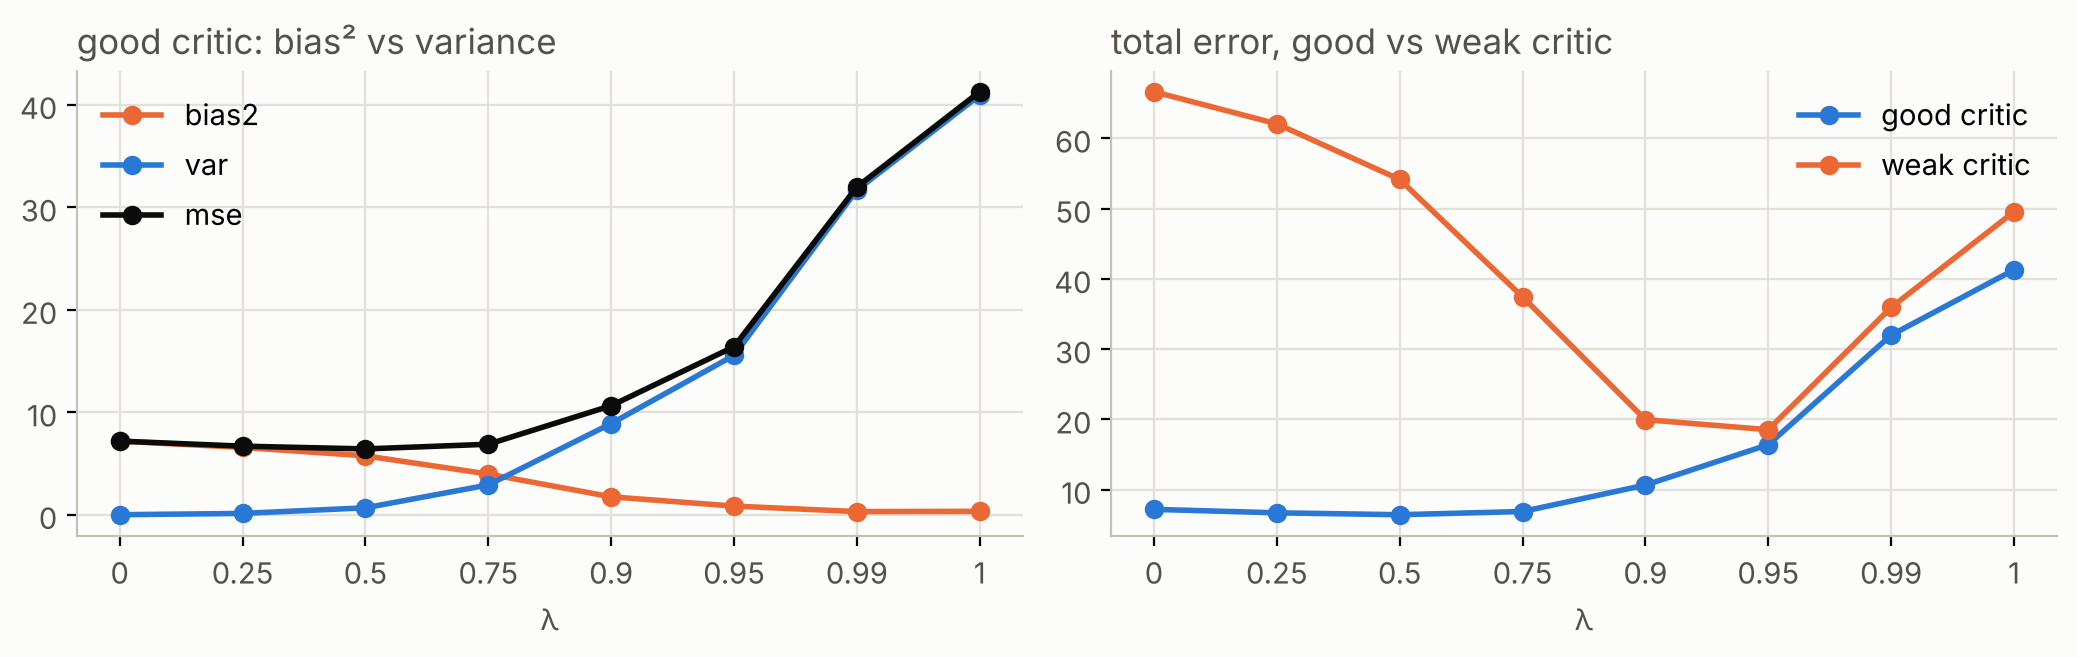

In [17]:
fig, ax = plt.subplots(1, 2, figsize=(10.5, 3.4)); xi = np.arange(len(lams))
g = gae_res["good"]
for k, c in [("bias2", ORANGE), ("var", BLUE), ("mse", INK)]:
    ax[0].plot(xi, g[k], "o-", color=c, label=k)
for tag, c in [("good", BLUE), ("weak", ORANGE)]:
    ax[1].plot(xi, gae_res[tag]["mse"], "o-", color=c, label=f"{tag} critic")
for a in ax:
    a.set_xticks(xi, [f"{l:g}" for l in lams]); a.set_xlabel("λ"); a.legend()
ax[0].set_title("good critic: bias² vs variance", loc="left", color=INK2)
ax[1].set_title("total error, good vs weak critic", loc="left", color=INK2)
plt.tight_layout(); plt.show()

**What the numbers say.** Bias falls and variance rises with λ, exactly as the theory says. With the good
critic (explained variance 0.943) the total error is lowest at λ = 0.5;
with the weak critic (0.919) the optimum moves to λ = 0.95. The less you
can trust the critic, the further you should look ahead with real rewards.

Two honest caveats. (1) The variance at λ = 0 is exactly zero here because the pendulum is deterministic
and the first action is fixed - in a noisy plant it would not be. (2) Bias² at λ = 1 is not exactly zero
(0.33) because the "truth" is itself an average of 1024 rollouts: that is the noise floor of
the measurement. The common default λ = 0.95 is a deliberate lean towards low bias: early in training the
critic is poor, and variance can be beaten with bigger batches while bias cannot.

## 7. Experiments on the pendulum: what each piece buys

Every configuration below changes **one** thing from the default and is trained with 3 seeds for 120 k
steps. "Final" is the mean of the last three evaluations (deterministic policy, 32 episodes each); "solved"
counts seeds whose evaluation return passed −250 within the budget.

The runs are independent, so on Linux they are spread over worker processes (each run seeds itself, so
the results do not depend on the number of workers).

In [18]:
N_SEEDS = 3
SEEDS = list(range(N_SEEDS))
PEND = {
    "clip": {}, "none": {"algo": "none"}, "vpg": {"algo": "none", "epochs": 1, "n_mb": 1},
    "kl": {"algo": "kl"}, "trpo": {"algo": "trpo"},
    "clip_ep1": {"epochs": 1}, "clip_ep3": {"epochs": 3}, "clip_ep30": {"epochs": 30},
    "none_ep3": {"algo": "none", "epochs": 3},
    "clip_005": {"clip": 0.05}, "clip_04": {"clip": 0.4},
    "lam_0": {"lam": 0.0}, "lam_05": {"lam": 0.5}, "lam_1": {"lam": 1.0},
    "no_adv_norm": {"adv_norm": False}, "no_obs_norm": {"obs_norm": False},
    "no_rew_scale": {"rew_scale": False}, "no_ortho": {"ortho": False},
    "no_anneal": {"anneal": False}, "value_clip": {"vclip": 0.2},
}
KEEP = ["step", "eval_return", "eval_step", "approx_kl", "clip_frac", "std", "expl_var", "wall"]

def run_pend(job):
    name, seed = job
    cfg = dict(PEND[name]); cfg["seed"] = seed
    if seed == 0 and name in ("clip", "none"):
        cfg["record_update"] = 10
    _, _, h = train(cfg)
    out = {k: h[k] for k in KEEP}
    out["ratios"] = h["ratios"]
    return name, seed, out

jobs = [(n, s) for n in PEND for s in SEEDS]
t0 = time.time()
if sys.platform.startswith("linux"):
    import multiprocessing as mp
    with mp.get_context("fork").Pool(2) as pool:
        out = pool.map(run_pend, jobs)
else:
    out = [run_pend(j) for j in jobs]
RUNS = {}
for n, s, h in out:
    RUNS.setdefault(n, {})[s] = h
print(f"{len(jobs)} runs in {time.time()-t0:.0f} s")

60 runs in 505 s


In [19]:
def summary(name):
    d = RUNS[name]
    fin = [np.mean(h["eval_return"][-3:]) for h in d.values()]
    hits = []
    for h in d.values():
        ev, st = np.array(h["eval_return"]), np.array(h["eval_step"])
        hits.append(int(st[np.argmax(ev > -250)]) if (ev > -250).any() else None)
    kl = max(max(h["approx_kl"]) for h in d.values())
    return np.mean(fin), np.std(fin), sum(x is not None for x in hits), hits, kl

print(f"{'config':14s} {'final':>8s} {'± sd':>7s}  solved  {'max KL':>7s}  steps to -250")
for n in PEND:
    m, s, k, hits, kl = summary(n)
    print(f"{n:14s} {m:8.1f} {s:7.1f}   {k}/{len(SEEDS)}   {kl:7.3f}  {hits}")

config            final    ± sd  solved   max KL  steps to -250
clip             -174.9     2.7   3/3     0.020  [40960, 32768, 40960]
none            -1009.0   115.9   0/3     9.071  [None, None, None]
vpg             -1201.2    10.1   0/3     0.000  [None, None, None]
kl               -168.4     4.8   3/3     0.102  [32768, 40960, 40960]
trpo             -169.2     4.3   3/3     0.010  [40960, 40960, 40960]
clip_ep1        -1099.7     8.8   0/3     0.004  [None, None, None]
clip_ep3         -472.5   126.5   0/3     0.011  [None, None, None]
clip_ep30        -181.8    16.8   3/3     0.042  [40960, 65536, 24576]
none_ep3        -1072.1     9.3   0/3     0.367  [None, None, None]
clip_005         -193.7    12.4   3/3     0.003  [73728, 65536, 73728]
clip_04          -175.3     7.6   3/3     0.134  [32768, 32768, 49152]
lam_0            -284.0    45.3   1/3     0.058  [None, 57344, None]
lam_05           -185.3    17.3   3/3     0.037  [49152, 73728, 49152]
lam_1            -191.5     3.

### 7.1 Reuse needs a trust region
Compare three rows: `vpg` (one gradient step per batch, no clip), `none` (10 epochs, no clip) and `clip`
(10 epochs, clipped).

* **Vanilla PG** ends at -1201.2: one gradient step per 2 048 samples is far too little
  learning per sample.
* **Ten unclipped epochs** reach -1009.0 with a large spread (±115.9) and a
  largest KL of 9.071 in a single update - the surrogate is being exploited.
* **Ten clipped epochs** reach -174.9 (±2.7), all seeds below −250 within
  about 40 k steps, and the KL never exceeds 0.02.

The ratio record from update 11 shows the mechanism directly.

none  mean |r-1| per epoch: 0.084 0.221 0.303 0.351 0.399 0.352 0.350 0.397 0.341 0.358   | outside [0.8,1.2] after epoch 10: 56%   | max ratio 9.19
clip  mean |r-1| per epoch: 0.018 0.110 0.063 0.094 0.090 0.105 0.101 0.119 0.122 0.105   | outside [0.8,1.2] after epoch 10: 16%   | max ratio 1.77


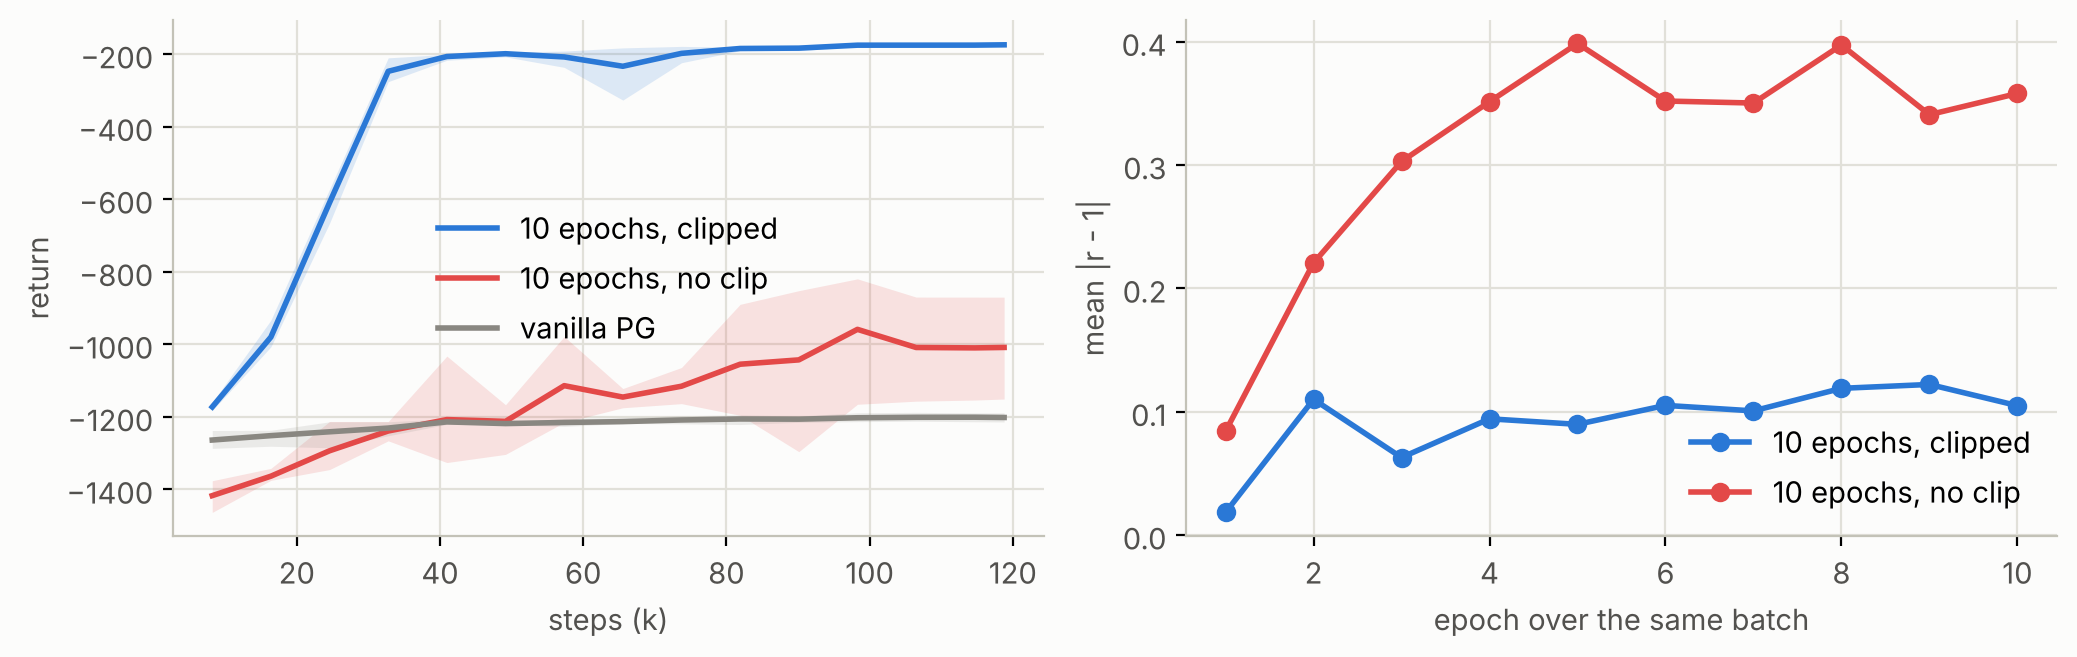

In [20]:
for name in ["none", "clip"]:
    rs = RUNS[name][0]["ratios"]
    dev = [np.mean(np.abs(r - 1)) for r in rs]
    print(f"{name:5s} mean |r-1| per epoch: " + " ".join(f"{d:.3f}" for d in dev)
          + f"   | outside [0.8,1.2] after epoch 10: {np.mean(np.abs(rs[-1]-1) > 0.2)*100:.0f}%"
          + f"   | max ratio {rs[-1].max():.2f}")

fig, ax = plt.subplots(1, 2, figsize=(10.5, 3.4))
for n, c, lab in [("clip", BLUE, "10 epochs, clipped"), ("none", RED, "10 epochs, no clip"), ("vpg", MUTED, "vanilla PG")]:
    d = RUNS[n]; x = np.array(d[0]["eval_step"]) / 1e3; Y = np.array([d[s]["eval_return"] for s in d])
    ax[0].plot(x, Y.mean(0), color=c, label=lab); ax[0].fill_between(x, Y.min(0), Y.max(0), color=c, alpha=.15, lw=0)
    if n != "vpg":
        ax[1].plot(range(1, 11), [np.mean(np.abs(r - 1)) for r in RUNS[n][0]["ratios"]], "o-", color=c, label=lab)
ax[0].set_xlabel("steps (k)"); ax[0].set_ylabel("return"); ax[0].legend()
ax[1].set_xlabel("epoch over the same batch"); ax[1].set_ylabel("mean |r - 1|"); ax[1].legend()
plt.tight_layout(); plt.show()

Without the clip the ratio drifts by about 0.35 on average and 56 %
of the samples end outside $[0.8,1.2]$; with it the drift stays near 0.1. (Some samples still end outside
the band even with clipping: the clip removes the *gradient* that would push them further, but the shared
network weights can still move them. That is why the clip is a soft trust region, not a hard one.)

### 7.2 Clip vs KL penalty vs TRPO

clip  final  -174.9 ±  2.7   median KL/update 0.0066   max 0.020   wall 17.9 s
kl    final  -168.4 ±  4.8   median KL/update 0.0089   max 0.102   wall 17.0 s
trpo  final  -169.2 ±  4.3   median KL/update 0.0084   max 0.010   wall 12.8 s


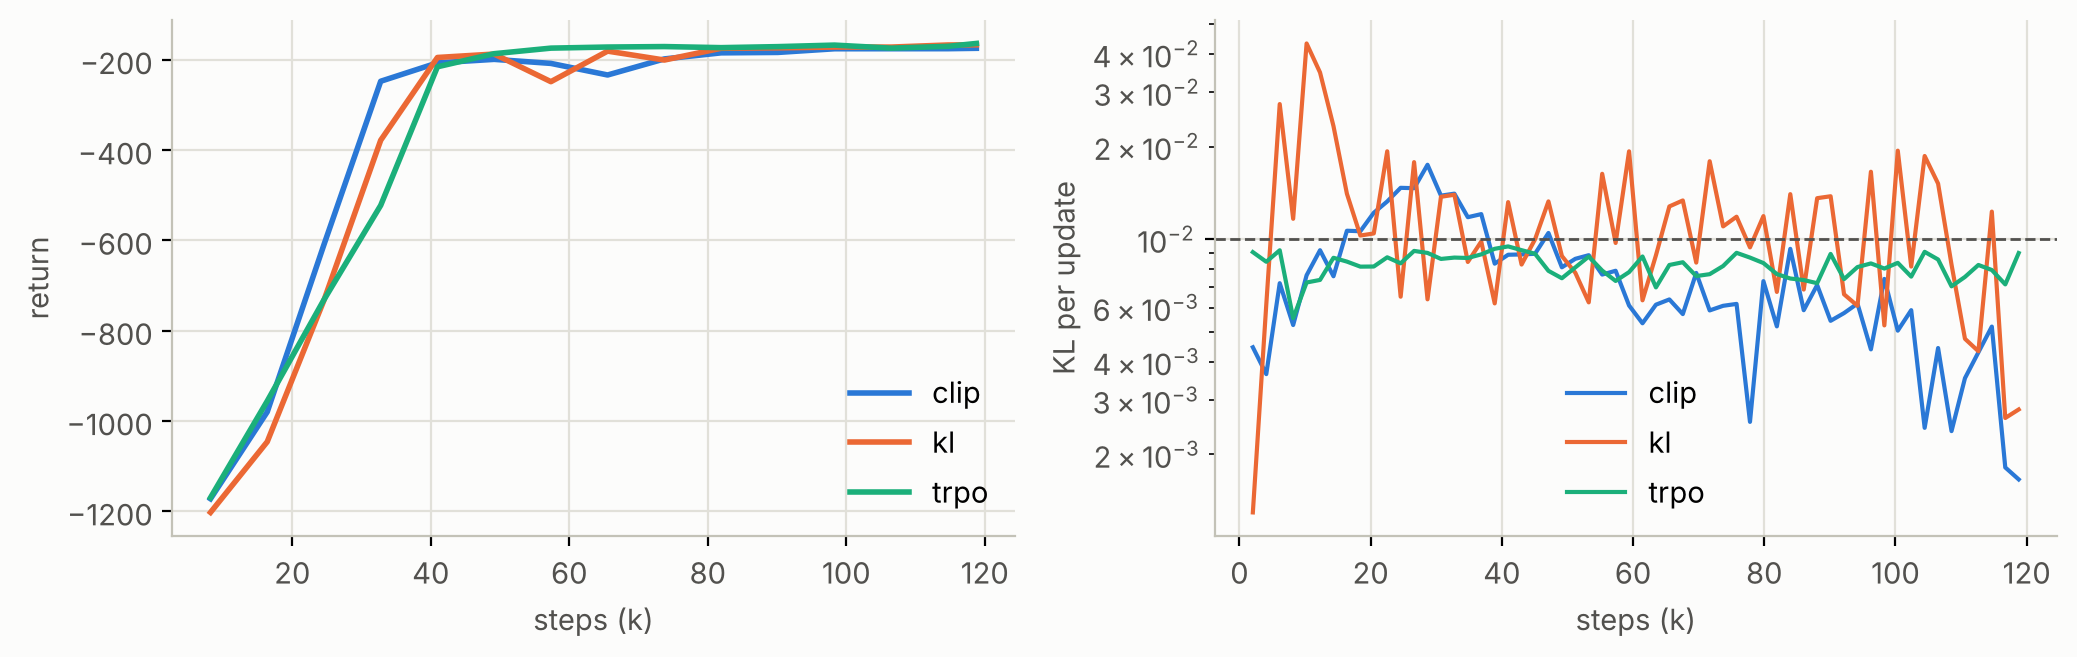

In [21]:
fig, ax = plt.subplots(1, 2, figsize=(10.5, 3.4))
for n, c in [("clip", BLUE), ("kl", ORANGE), ("trpo", AQUA)]:
    d = RUNS[n]; x = np.array(d[0]["eval_step"]) / 1e3; Y = np.array([d[s]["eval_return"] for s in d])
    ax[0].plot(x, Y.mean(0), color=c, label=n)
    ax[1].plot(np.array(d[0]["step"]) / 1e3, np.mean([d[s]["approx_kl"] for s in d], 0), color=c, label=n, lw=1.5)
    m, s, k, hits, kl = summary(n)
    print(f"{n:5s} final {m:7.1f} ± {s:4.1f}   median KL/update {np.median(np.concatenate([h['approx_kl'] for h in d.values()])):.4f}"
          f"   max {kl:.3f}   wall {np.mean([h['wall'][-1] for h in d.values()]):.1f} s")
ax[1].axhline(0.01, ls="--", color=INK2, lw=1); ax[1].set_yscale("log")
ax[0].set_xlabel("steps (k)"); ax[0].set_ylabel("return"); ax[0].legend()
ax[1].set_xlabel("steps (k)"); ax[1].set_ylabel("KL per update"); ax[1].legend()
plt.tight_layout(); plt.show()

All three reach the same place (-174.9, -168.4, -169.2) at
the same speed. They differ in how they hold the KL: TRPO pins it just under δ = 0.01 by construction
(max 0.01); PPO-clip lands in the same range *without ever computing a KL in the loss*; the
adaptive penalty oscillates as β chases the target and lets single updates overshoot to 0.102.

That is the practical case for PPO-clip: TRPO's stability with first-order code, minibatches, any optimiser
and any architecture (shared trunks, recurrent policies, dropout). The large-scale study of Engstrom et al.
(2020) adds an important footnote: much of PPO's advantage over TRPO in the original benchmarks came from
**implementation details** rather than the clip itself. §7.4 tests some of those.

### 7.3 Epochs, clip range and λ

In [22]:
def row(names, label):
    print(label)
    for n in names:
        m, s, k, hits, kl = summary(n)
        print(f"   {n:10s} final {m:8.1f} ± {s:5.1f}   solved {k}/{len(SEEDS)}   max KL {kl:.3f}")
row(["clip_ep1", "clip_ep3", "clip", "clip_ep30"], "epochs K (clipped, eps=0.2):")
row(["vpg", "none_ep3", "none"], "epochs K (no clip; vpg = 1 step):")
row(["clip_005", "clip", "clip_04"], "clip range eps (K=10):")
row(["lam_0", "lam_05", "clip", "lam_1"], "GAE lambda (clip = 0.95):")

epochs K (clipped, eps=0.2):
   clip_ep1   final  -1099.7 ±   8.8   solved 0/3   max KL 0.004
   clip_ep3   final   -472.5 ± 126.5   solved 0/3   max KL 0.011
   clip       final   -174.9 ±   2.7   solved 3/3   max KL 0.020
   clip_ep30  final   -181.8 ±  16.8   solved 3/3   max KL 0.042
epochs K (no clip; vpg = 1 step):
   vpg        final  -1201.2 ±  10.1   solved 0/3   max KL 0.000
   none_ep3   final  -1072.1 ±   9.3   solved 0/3   max KL 0.367
   none       final  -1009.0 ± 115.9   solved 0/3   max KL 9.071
clip range eps (K=10):
   clip_005   final   -193.7 ±  12.4   solved 3/3   max KL 0.003
   clip       final   -174.9 ±   2.7   solved 3/3   max KL 0.020
   clip_04    final   -175.3 ±   7.6   solved 3/3   max KL 0.134
GAE lambda (clip = 0.95):
   lam_0      final   -284.0 ±  45.3   solved 1/3   max KL 0.058
   lam_05     final   -185.3 ±  17.3   solved 3/3   max KL 0.037
   clip       final   -174.9 ±   2.7   solved 3/3   max KL 0.020
   lam_1      final   -191.5 ±   3.4   solv

* **Epochs.** With the clip, more epochs turn into faster learning: K = 1 → -1099.7,
  K = 3 → -472.5, K = 10 → -174.9, and K = 30 is no better
  (-181.8) while taking about 35.5 s instead of 16.7 s.
  Without it, 3 epochs already give a KL of 0.367 and very little progress.
* **Clip range.** ε = 0.05 is safe but slow (KL never above 0.003, and it takes roughly
  twice as many steps to reach −250); ε = 0.4 is as fast as 0.2 here but allows single-update KLs of
  0.134. 0.1-0.2 is the usual band.
* **λ.** λ = 0 solves only 1 of 3 seeds (final -284.0): one-step TD
  advantages carry the young critic's bias straight into the policy. λ = 0.5, 0.95 and 1.0 all work, with
  0.95 best and slightly ahead of 1.0 (more variance) - consistent with §6.6.

### 7.4 Which implementation details matter?
Huang et al. (2022) list 37 implementation details in the reference PPO code; Andrychowicz et al. (2021)
ran a 250 000-run study of which ones matter. Here we switch six of them off (or, for value clipping,
on) one at a time:

In [23]:
rows = [("all details on (default)", "clip"), ("- reward scaling", "no_rew_scale"), ("+ value clipping", "value_clip"),
        ("- lr annealing", "no_anneal"), ("- advantage normalisation", "no_adv_norm"),
        ("- observation normalisation", "no_obs_norm"), ("- orthogonal init", "no_ortho")]
for lab, n in rows:
    m, s, k, hits, kl = summary(n)
    print(f"{lab:30s} final {m:8.1f} ± {s:5.1f}   solved {k}/{len(SEEDS)}")

all details on (default)       final   -174.9 ±   2.7   solved 3/3
- reward scaling               final   -385.9 ±  97.8   solved 0/3
+ value clipping               final   -217.6 ±  30.5   solved 3/3
- lr annealing                 final   -198.2 ±  21.2   solved 3/3
- advantage normalisation      final   -174.1 ±  10.8   solved 3/3
- observation normalisation    final   -169.9 ±   5.7   solved 3/3
- orthogonal init              final   -168.2 ±   1.9   solved 3/3


An honest result, and the important lesson of this section: **on this task most details do nothing
measurable**, and one matters enormously.

* **Reward scaling** is essential here: without it the final return is -385.9 and no seed
  reaches −250. The pendulum's per-step cost reaches about −16, so discounted returns are of order
  −100 to −300; the critic must regress onto targets of that size with a learning rate tuned for unit-scale
  targets, the value loss dominates the shared gradient-norm clip, and the advantages are noisy for a long
  time.
* **Value clipping** makes things *worse* (-217.6), in line with Andrychowicz et al. (2021),
  who found it does not help and sometimes hurts.
* **Removing lr annealing** costs a little (-198.2, more spread): late updates stay large.
* Advantage normalisation, observation normalisation and orthogonal init make no difference within seed
  noise **on this problem** - the pendulum's observations are already of unit scale, and advantages are
  normalised implicitly by the reward scaling. On the quadrotor or on robots with raw sensor units
  (millimetres, newtons, rad/s) observation normalisation becomes important.

The transferable rule is not "always use these 37 tricks" but **ablate one change at a time over several
seeds before believing it**. Three seeds is a minimum; Henderson et al. (2018) show how badly 1-2 seeds can
mislead.

## 8. The quadrotor: a full run and its diagnostics

The same trainer, now on the 9-dimensional quadrotor with 16 environments × 256 steps (4 096 samples per
batch), γ = 0.99, lr 3e-4 annealed, 4 minibatches, 800 k steps. We run it twice:

* **healthy**: the defaults above (K = 10, ε = 0.2);
* **aggressive**: K = 30, ε = 0.4, lr 1e-3 and no annealing - a set of choices that each look like "learn
  faster", and that a student under deadline pressure might well try.

Both log the four diagnostics on every update. (About 2.5 minutes.)

In [24]:
QUAD_BASE = dict(env="quad", n_envs=16, n_steps=256, total=800_000, gamma=0.99, lam=0.95,
                 lr=3e-4, n_mb=4, epochs=10)
QUAD = {"healthy": {}, "aggressive": {"epochs": 30, "clip": 0.4, "lr": 1e-3, "anneal": False},
        "no_rew_scale": {"rew_scale": False}}

def run_quad(name):
    cfg = dict(QUAD_BASE); cfg.update(QUAD[name])
    ac, on, h = train(cfg, eval_every=10)
    ret, crash = evaluate(ac, PlanarQuad, on, n=100)
    return name, h, ret, crash, ac, on

t0 = time.time()
if sys.platform.startswith("linux"):
    with mp.get_context("fork").Pool(2) as pool:
        qout = pool.map(run_quad, list(QUAD))
else:
    qout = [run_quad(n) for n in QUAD]
QH = {}
for name, h, ret, crash, ac_, on_ in qout:
    QH[name] = h
    print(f"{name:13s} final return {ret:6.1f}  crash rate {crash*100:5.1f}%  peak eval {max(h['eval_return']):6.1f}"
          f"  max KL {max(h['approx_kl']):8.3f}  final std {h['std'][-1]:.3f}")
quad_ac, quad_on = qout[0][4], qout[0][5]
print(f"({time.time()-t0:.0f} s)")

healthy       final return  217.2  crash rate   0.0%  peak eval  218.0  max KL    0.012  final std 0.281
aggressive    final return    0.8  crash rate 100.0%  peak eval  218.0  max KL  154.374  final std 0.014
no_rew_scale  final return  211.6  crash rate   0.0%  peak eval  210.8  max KL    0.011  final std 0.429
(113 s)


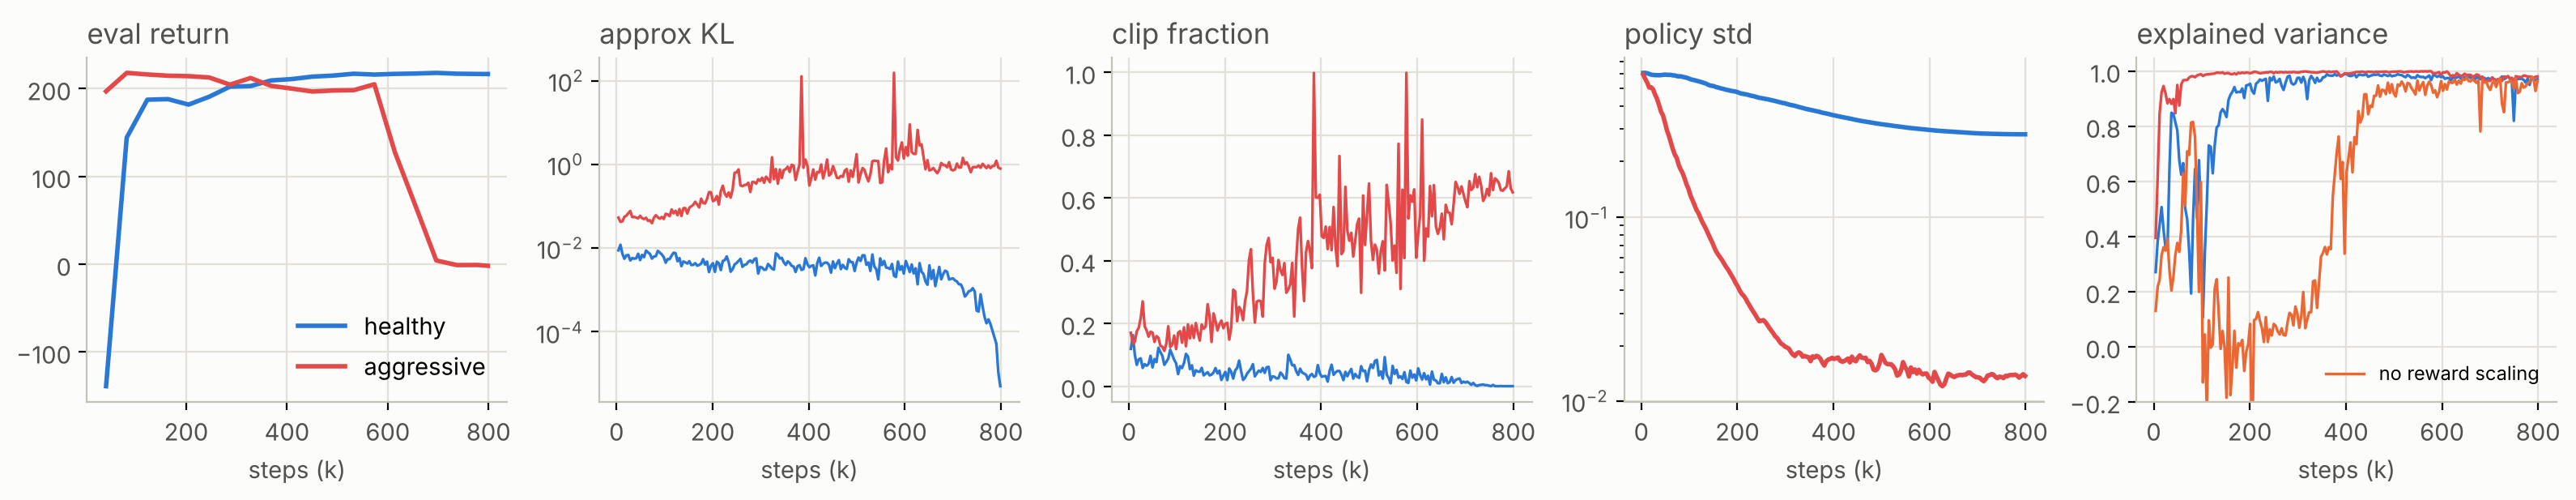

aggressive run:
  KL first above 0.05 at          4096 steps
  policy std first below 0.05   184320 steps
  peak evaluation return       218.0 at 81920 steps
  return falls below 150 at    614400 steps


In [25]:
fig, ax = plt.subplots(1, 5, figsize=(16, 3.2))
for n, c in [("healthy", BLUE), ("aggressive", RED)]:
    h = QH[n]; s = np.array(h["step"]) / 1e3
    ax[0].plot(np.array(h["eval_step"]) / 1e3, h["eval_return"], color=c, label=n)
    ax[1].plot(s, h["approx_kl"], color=c, lw=1.2); ax[2].plot(s, h["clip_frac"], color=c, lw=1.2)
    ax[3].plot(s, h["std"], color=c); ax[4].plot(s, h["expl_var"], color=c, lw=1.2)
ax[4].plot(np.array(QH["no_rew_scale"]["step"]) / 1e3, QH["no_rew_scale"]["expl_var"], color=ORANGE, lw=1.2, label="no reward scaling")
ax[1].set_yscale("log"); ax[3].set_yscale("log"); ax[4].set_ylim(-0.2, 1.05)
for a, t in zip(ax, ["eval return", "approx KL", "clip fraction", "policy std", "explained variance"]):
    a.set_title(t, loc="left", color=INK2); a.set_xlabel("steps (k)")
ax[0].legend(); ax[4].legend(fontsize=8.5)
plt.tight_layout(); plt.show()

h = QH["aggressive"]; st = np.array(h["step"]); es = np.array(h["eval_step"]); ev = np.array(h["eval_return"])
pk = int(np.argmax(ev)); after = np.where((es > es[pk]) & (ev < 150))[0]
print("aggressive run:")
print(f"  KL first above 0.05 at       {st[np.argmax(np.array(h['approx_kl']) > 0.05)]:7d} steps")
print(f"  policy std first below 0.05  {st[np.argmax(np.array(h['std']) < 0.05)]:7d} steps")
print(f"  peak evaluation return       {ev[pk]:.1f} at {es[pk]} steps")
print(f"  return falls below 150 at    {es[after[0]] if len(after) else None} steps")

**Read the aggressive run left to right.** Its return curve looks *better* than the healthy one for
hundreds of thousands of steps - it reaches 190 after 40 k steps versus
245 k, and peaks at 218.0. Anyone watching only the return
would keep these settings. Then, around 614 k steps, it falls apart and ends
at 0.8 with a 100 % crash rate.

The other panels saw it coming:

* **approx. KL** was above 0.05 from the very first update and climbed past 1 - every update was replacing
  the policy rather than adjusting it (single updates reached 154.374);
* **clip fraction** rose to about 0.638 - most samples were outside the trust region, so
  most of the batch was contributing no gradient;
* **policy std** fell below 0.05 by 184 k steps and ended at
  0.014 (healthy: 0.281). With almost no exploration the advantages
  become noise, and with ε = 0.4 and 30 epochs there is nothing to stop one bad batch from moving the policy
  somewhere it cannot recover from.

**Explained variance** $1-\operatorname{Var}[\hat R-V]/\operatorname{Var}[\hat R]$ tells you whether the
critic is doing its job. Without reward scaling it averages 0.42 over the first 20
updates (healthy: 0.53), and that run takes 327 k steps
instead of 245 k to reach a return of 190 - it still gets there, because the
quadrotor's rewards are of order 1 per step already.

### Diagnostic cheat sheet

| signal | healthy range (rough) | too high means | too low means |
|---|---|---|---|
| approx. KL per update | 0.002-0.03 | steps too big: lower lr, fewer epochs, smaller ε | learning stalled: raise lr or check advantages are not ~0 |
| clip fraction | 0.05-0.25 | same as high KL | clip never active - you could take bigger steps |
| policy std / entropy | decays slowly | slow convergence, consider lower initial std | premature collapse - raise std floor or entropy bonus, lower lr |
| explained variance | rising towards 0.9+ | - | critic not learning: scale rewards, check bootstrapping, raise value lr |
| grad norm before clipping | stable | exploding loss scale (often unscaled rewards) | - |

These ranges are rules of thumb from common practice, not laws - calibrate them on a run you trust.

healthy policy from (x, z, pitch) = (-1.0 m, 0.4 m, 0.3 rad): position error over the last second 1.78 cm; first inside 5 cm after 2.24 s


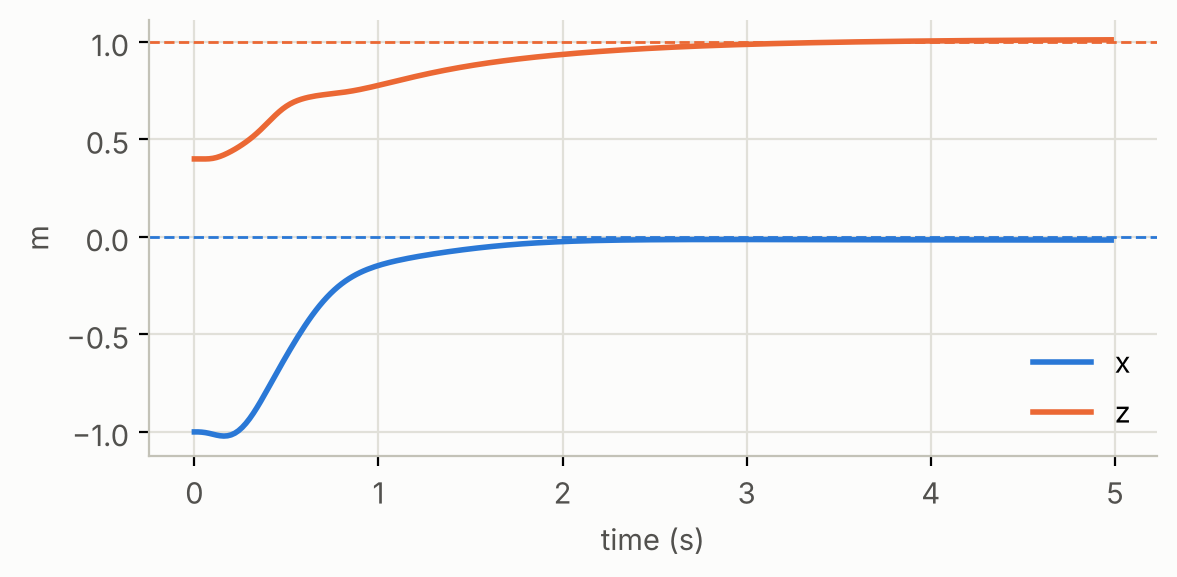

In [26]:
env = PlanarQuad(1, seed=0); env.s[0] = [-1.0, 0.4, 0.3, 0, 0, 0]; o = env.obs(); tr = []
for t in range(env.T):
    with torch.no_grad():
        a = quad_ac.dist(torch.as_tensor(quad_on(o))).mean.numpy()
    tr.append(env.s[0].copy()); o, *_ = env.step(a)
tr = np.array(tr); e = np.hypot(tr[:, 0], tr[:, 1] - 1)
print(f"healthy policy from (x, z, pitch) = (-1.0 m, 0.4 m, 0.3 rad): position error over the last second "
      f"{e[-50:].mean()*100:.2f} cm; first inside 5 cm after {np.argmax(e < 0.05)*0.02:.2f} s")
plt.figure(figsize=(6, 3)); tt = np.arange(len(tr)) * 0.02
plt.plot(tt, tr[:, 0], color=BLUE, label="x"); plt.plot(tt, tr[:, 1], color=ORANGE, label="z")
plt.axhline(1, ls="--", color=ORANGE, lw=1); plt.axhline(0, ls="--", color=BLUE, lw=1)
plt.xlabel("time (s)"); plt.ylabel("m"); plt.legend(); plt.tight_layout(); plt.show()

## 9. What to remember: a PPO protocol

1. **Get the bootstrap right.** Time-outs bootstrap from $V$ of the true final state; crashes do not.
   Store the final observation *before* the environment auto-resets.
2. **Scale rewards** by the running std of the discounted return. Check explained variance in the first
   few updates; if it is near zero, the critic is not learning and nothing else will work.
3. **Choose λ for your critic.** 0.95 is a sound default; lower it only if the critic is demonstrably good.
4. **Clip, and let it work.** ε = 0.1-0.2, K = 3-10 epochs, a few minibatches. More epochs are only
   free while the clip fraction stays moderate.
5. **Watch KL, clip fraction, policy std and explained variance**, not just return. A rising KL and a
   collapsing std predict failure long before the return curve shows it.
6. **Anneal the learning rate**, clip the gradient norm, normalise advantages per minibatch - cheap
   insurance, even when an ablation on one task shows no effect.
7. **Ablate one change at a time with ≥ 3 seeds.** Most "tricks" are task-dependent; measure before you
   believe.
8. **PPO-clip ≈ TRPO with first-order code.** If you need a hard guarantee on step size, add early stopping
   on the measured KL (stop the epoch loop when KL > 1.5 × target) - see exercise 3.

## 10. Exercises

1. **Bootstrap bug.** In `Rollout.collect`, replace `v_next` for time-outs with 0 (treat truncation as
   termination). Train the quadrotor. What happens to explained variance and to the hover height? Why does
   the bug matter more for γ = 0.99 than for γ = 0.95?
2. **Entropy bonus.** Set `ent_coef` to 0.0, 0.005 and 0.02 for the *aggressive* quadrotor configuration.
   Does an entropy bonus prevent the collapse, delay it, or neither? Plot policy std for each.
3. **KL early stopping.** Add `target_kl` to `ppo_update`: stop the epoch loop once the mean approx. KL of an
   epoch exceeds 1.5 × `target_kl`. Re-run the aggressive configuration with `target_kl = 0.02`. How many
   epochs are actually used per update, and does the collapse disappear?
4. **State-dependent std.** Replace the free `log_std` parameter with a second output head. Compare final
   pendulum return and the policy std near the upright position versus hanging down. Is the extra
   flexibility used?
5. **Exact vs approximate KL.** Log the exact Gaussian $D_{\text{KL}}(\pi_{\text{old}}\|\pi_\theta)$ alongside the
   estimator $(r-1)-\log r$ during one pendulum run. How close are they, and when do they disagree?
6. **GAE with a noisy plant.** Add Gaussian torque noise (σ = 0.2 N·m) to the pendulum and repeat the
   §6.6 measurement. Is the variance at λ = 0 still zero? Where does the optimal λ move?
7. **Sample efficiency vs wall time.** For K ∈ {1, 3, 10, 30}, plot return against *environment steps*
   and against *wall-clock seconds*. Which K is best when simulation is cheap, and which when each step is a
   real robot step costing 20 ms?
8. **Domain randomisation, revisited.** Train the quadrotor with motor lag drawn from U(0, 80 ms) per
   episode (see the RL lecture). Which diagnostic changes most compared with the nominal run, and why?

## 11. References

* J. Schulman, F. Wolski, P. Dhariwal, A. Radford, O. Klimov, "Proximal Policy Optimization Algorithms,"
  arXiv:1707.06347, 2017.
* J. Schulman, S. Levine, P. Moritz, M. Jordan, P. Abbeel, "Trust Region Policy Optimization," *ICML* 2015.
* J. Schulman, P. Moritz, S. Levine, M. Jordan, P. Abbeel, "High-Dimensional Continuous Control Using
  Generalized Advantage Estimation," *ICLR* 2016.
* R. J. Williams, "Simple statistical gradient-following algorithms for connectionist reinforcement
  learning," *Machine Learning* 8, 229-256, 1992.
* S. Kakade, "A Natural Policy Gradient," *NeurIPS* 2001; S. Kakade, J. Langford, "Approximately Optimal
  Approximate Reinforcement Learning," *ICML* 2002.
* L. Engstrom, A. Ilyas, S. Santurkar, D. Tsipras, F. Janoos, L. Rudolph, A. Madry, "Implementation Matters
  in Deep Policy Gradients: A Case Study on PPO and TRPO," *ICLR* 2020.
* M. Andrychowicz et al., "What Matters for On-Policy Deep Actor-Critic Methods? A Large-Scale Study,"
  *ICLR* 2021.
* S. Huang, R. F. J. Dossa, A. Raffin, A. Kanervisto, W. Wang, "The 37 Implementation Details of Proximal
  Policy Optimization," *ICLR Blog Track* 2022.
* P. Henderson, R. Islam, P. Bachman, J. Pineau, D. Precup, D. Meger, "Deep Reinforcement Learning that
  Matters," *AAAI* 2018.
* J. Achiam, "Spinning Up in Deep RL" (OpenAI documentation), 2018 - PPO and TRPO pages.
* R. S. Sutton, A. G. Barto, *Reinforcement Learning: An Introduction*, 2nd ed., MIT Press, 2018, ch. 13.

Generated by Claude and customized by

<div align="center">
<img src="https://raw.githubusercontent.com/dewdotninja/sharing-github/refs/heads/master/dewninja_logo50.jpg" alt="dewninja"/>
</div>
<div align="center">dew.ninja 2026</div>